In [17]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from dotenv import load_dotenv
import re
import json
from pathlib import Path
import pandas


load_dotenv()


dictionary_with_rules = {}
if Path("rules.json").exists():
    with open("rules.json", "r", encoding="utf-8") as file:
        dictionary_with_rules = json.load(file)
else:
    with open("rules.txt", "r", encoding="utf-8") as file:
        text = file.read()

    chunks = text.split("\n\n\n")
    chunks = chunks[2:]


    for chunk in chunks:
        parts_of_chunk = chunk.split("\n\n")
        if len(parts_of_chunk) < 2:
            continue
        header = parts_of_chunk[0].strip()
        body = parts_of_chunk[1].strip()
        dictionary_with_rules[header] = body

    with open("rules.json", "w", encoding="utf-8") as file:
        json.dump(dictionary_with_rules, file, ensure_ascii=False, indent=2)



embeddings_own = OpenAIEmbeddings(model="text-embedding-3-large")

if Path("vector_store.json").exists():
    store = InMemoryVectorStore.load("vector_store.json", embeddings_own)
else:
    store = InMemoryVectorStore(embeddings_own)

    docs = []
    for i in dictionary_with_rules:
        docs.append(Document(i, metadata={"source": "rules.json", "text": dictionary_with_rules[i]}))
    store.store.clear()
    store.add_documents(documents=docs)
    store.dump("vector_store.json")



data_frame = pandas.read_excel("test_attributes.xlsx")

In [2]:
from langchain.tools import tool

@tool
def convert_bar_to_mpa(value_bar: float) -> float:
    """Convert pressure from bar to megapascals (MPa). 1 bar = 0.1 MPa."""
    return round(value_bar * 0.1, 2)

@tool
def convert_psi_to_mpa(value_psi: float) -> float:
    """Convert pressure from psi to megapascals (MPa). 1 psi = 0.006895 MPa."""
    return round(value_psi * 0.006895, 2)

@tool
def convert_inch_to_mm(value_inch: float) -> float:
    """Convert length from inches to millimetres. 1 inch = 25.4 mm."""
    return round(value_inch * 25.4, 2)

@tool
def convert_lb_to_kg(value_lb: float) -> float:
    """Convert weight from pounds to kilograms. 1 lb = 0.4536 kg."""
    return round(value_lb * 0.4536, 2)

@tool
def convert_kelvin_to_celsius(value_k: float) -> float:
    """Convert temperature from Kelvin to Celsius."""
    return round(value_k - 273.15, 2)

@tool
def convert_fahrenheit_to_celsius(value_f: float) -> float:
    """Convert temperature from Fahrenheit to Celsius."""
    return round((value_f - 32) * 5 / 9, 2)

In [12]:
SYSTEM_PROMPT1 = """
You are a data normalization engine.

Your task is to normalize the provided attribute value using ONLY the supplied technical rules.

General rules:
- Use only the provided rules as the source of normalization decisions.
- Evaluate every retrieved rule before deciding whether it applies.
- Apply every applicable rule to the value.
- Apply substitutions sequentially until all applicable rules have been processed.
- Ignore any line starting with "Reference:" because it is documentation only and must never affect the output.
- If no rule applies, return the original value unchanged.

Numeric output rules:
- When a rule requires converting a numeric value (e.g. Kelvin to Celsius, inches to millimetres, pounds to kilograms), compute the result precisely, then round to at most two decimal places.
- If the result is a whole number (no meaningful fractional part after rounding), output it without a decimal point or trailing zeros (e.g. "100", not "100.00" or "100.0").
- Always include the resulting unit or its accepted abbreviation as part of the output (e.g. "100 degrees Celsius", not just "100"), unless the rules explicitly specify a unit-free numeric code (such as a DN or PN value).
- Apply this numeric formatting consistently regardless of which rule section produced the conversion.

Substitution rules:
- A rule may express a substitution in different ways, including:
  - "X becomes Y"
  - "X is abbreviated as Y"
  - "Material codes are ..."
  - "The approved short form is ..."
  - "Use code ..."
  Whenever such a rule matches part of the value, replace only that matching part.
- Preserve all other information from the original value unless a rule explicitly changes it.
- Never remove, truncate, reorder, or invent information unless a rule explicitly instructs you to do so.

Formatting rules:
- If a rule demonstrates formatting using an example (for example "GOST-33259"), treat it as a formatting pattern only.
- Never copy literal example values into the output unless they already exist in the original value.
- Never replace a standard number, year, grade, code, or identifier with a different one mentioned elsewhere in the rules.
- Only modify separators, spacing, capitalization, abbreviations, or units when explicitly required by the rules.
- Reference lists of standard/typical values (e.g. a standard pressure series, a standard diameter series) describe valid ranges for validation purposes only — never copy their labels, prefixes, or exact phrasing into the output. The output must always be the computed or substituted value itself, not a label describing a category it falls into.

Output requirements:
- Return ONLY the final normalized value.
- Do not explain your reasoning.
- Do not summarize the rules.
- Do not output markdown.
- Do not output bullet lists.
- Do not output any extra text.

Examples:

Attribute: Body material
Value: Grey cast iron GG-20
Rules:
Material codes are GCI for grey cast iron, CS for carbon steel, and SS for stainless steel.
Output:
GCI GG-20

Attribute: Seal material
Value: Stainless steel 12Cr18Ni9Ti
Rules:
Material codes are GCI for grey cast iron, CS for carbon steel, and SS for stainless steel.
Output:
SS 12Cr18Ni9Ti

Attribute: End connection
Value: Flanged
Rules:
FLANGED becomes FLG.
Output:
FLG

Attribute: Valve type
Value: Gate valve, wedge
Rules:
GATE VALVE becomes GV.
Output:
GV, wedge

Attribute: Actuator type
Value: Electric actuator
Rules:
The actuator type is selected based on operating conditions and the required opening
torque. A manual handwheel is appropriate when the torque does not exceed 250 newton
metres. For higher torques, an electric or pneumatic actuator must be specified.
Actuator types must be recorded using the approved short form from the internal
reference list IS-002: MANUAL HANDWHEEL becomes MHW, ELECTRIC ACTUATOR becomes EA,
and PNEUMATIC ACTUATOR becomes PA. The minimum designated service life for pipeline
valves is 25 years, provided that installation, operation, and maintenance are
carried out in accordance with the manufacturer's instructions. Reference:
GOST 5762-2002, clause 3.7; GOST 53402-2009, clause 6.3.
Output:
EA

Attribute: Working medium temperature, K
Value: 373.15 K
Rules:
Temperature values must be recorded in degrees Celsius only. Kelvin and Fahrenheit
are not accepted. To convert from Kelvin, subtract 273.15.
Output:
100 degrees Celsius

Attribute: Flange standard
Value: GOST 12815-80
Rules:
Standard references must follow the format GOST-33259 or ASME-B16.5, without extra
spaces or punctuation.
Output:
GOST-12815-80
"""

SYSTEM_PROMPT2 = """
You are a routing assistant. Your only task is to decide which of two candidate
technical rule section names is the best semantic match for a given attribute name.

You will receive:
- The name of the attribute currently being processed.
- Two candidate section names retrieved from a vector database.

Decision rules:
- Base your decision only on the meaning of the attribute name compared to the two candidate section names.
- Choose the section whose subject matter most directly governs that attribute.
- If both candidates seem plausible, choose the one that is more specific to the attribute rather than the more general one.

Output requirements:
- Return ONLY the exact text of the chosen section name, copied character-for-character from the candidates you were given.
- Do not add quotes, numbering, punctuation, explanations, or any other text.
- Do not return anything other than one of the two candidate section names.
"""

In [13]:
from langgraph.graph import START, StateGraph, MessagesState, END
from IPython.display import display, Image
import pandas
from langchain_core.documents import Document
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from typing import Literal
from langchain_core.messages import HumanMessage, ToolMessage, RemoveMessage

model = ChatOpenAI(model="gpt-4o", temperature=0)

class MessagesState(MessagesState):
    new_data_frame: pandas.DataFrame
    i: int
    attribute: str
    value: str

def start_node(state: MessagesState) -> MessagesState:
    if state["i"] != 0:
        new_row = pandas.DataFrame([{"Attribute": state["attribute"],
                                     "Value": state["value"],
                                     "Rules_Value": state["messages"][-1].content}])

        state["new_data_frame"] = pandas.concat([state["new_data_frame"], new_row], ignore_index=True)

    if data_frame.shape[0] > state["i"]:
        state["attribute"] = data_frame.iloc[state["i"]]["Attribute"]
        state["value"] = data_frame.iloc[state["i"]]["Value"]
        state["messages"] = [RemoveMessage(id=k.id) for k in state["messages"]]

    return state;

def condition_edges_1(state: MessagesState) -> Literal["retrieve_context", "end_node"]:
    if state["i"] < data_frame.shape[0]:
        return "retrieve_context"
    else:
        return "end_node"

def condition_edges_2(state: MessagesState) -> Literal["tools", "start_node"]:
    last_message = state["messages"][-1]
    if getattr(last_message, "tool_calls", None):
        return "tools"
    return "start_node"



tools = [convert_bar_to_mpa, convert_psi_to_mpa, convert_inch_to_mm, convert_lb_to_kg, convert_kelvin_to_celsius, convert_fahrenheit_to_celsius]
llm_bind_tools = model.bind_tools(tools=tools)

def retrieve_context(state: MessagesState) -> MessagesState:
    """Retrieve information to help answer a query and return list of documents."""
    if state["messages"] and isinstance(state["messages"][-1], ToolMessage):
        new_inv = llm_bind_tools.invoke(state.get("messages") + [{"role": "system", "content": SYSTEM_PROMPT1}])
        return {"messages": [new_inv]}

    else:
        retrieved_documents = store.similarity_search(query = f"{state['attribute']}", k=2)
        candidate_headers = [doc.page_content for doc in retrieved_documents]
        candidates_text = "\n".join(f"{idx+1}. {header}" for idx, header in enumerate(candidate_headers))

        selection = model.invoke([
            {"role": "system", "content": SYSTEM_PROMPT2},
            {"role": "user", "content": f"Current attribute: {state['attribute']}\n\nCandidate section names:\n{candidates_text}"}
        ])
        selection = selection.content.strip()
        retrieved_document = next((item for item in retrieved_documents if item.page_content.strip() == selection), retrieved_documents[0])

        contexts = retrieved_document.metadata["text"]
        new_iteration = state.get("i") + 1
        inv = llm_bind_tools.invoke([{"role": "system", "content": SYSTEM_PROMPT1}, {"role": 'user', "content": f"Attribute: {state['attribute']}\nValue: {state['value']}\n\nRelevant rules:\n{contexts}"}])

        return {    "messages": [

        {"role": "user", "content": f"Attribute: {state['attribute']}\nValue: {state['value']}\n\nRelevant rules:\n{contexts}"},
        inv],
    "i": new_iteration}

def end_node(state: MessagesState) -> MessagesState:
    file = state.get("new_data_frame")
    file.to_excel("test_first_phase_table2.xlsx", index=False)
    return state

load_dotenv()

tools_node = ToolNode(tools)



builder = StateGraph(MessagesState)
builder.add_node(start_node)
builder.add_node(retrieve_context)
builder.add_node(end_node)
builder.add_node("tools", tools_node)
builder.add_edge(START, "start_node")
builder.add_conditional_edges("start_node", condition_edges_1)
builder.add_conditional_edges("retrieve_context", condition_edges_2)
builder.add_edge("tools", "retrieve_context")
builder.add_edge("end_node", END)

graph = builder.compile()

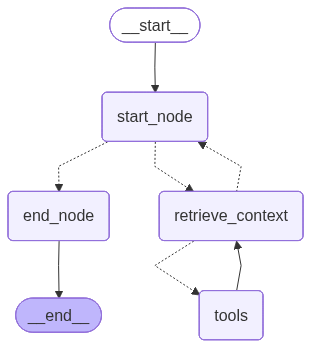

In [14]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
result = graph.invoke({"messages": [], 'new_data_frame': pandas.DataFrame(columns=["Attribute", "Value", "Rules_Value"]), "i":0})

for f in result["messages"]:
    f.pretty_print()

================================ Human Message =================================

Attribute: Nominal pressure, psi
Value: 232 psi

Relevant rules:
All pressure values in the system must be expressed exclusively in megapascals (MPa).
The use of bar, atm, kgf/cm2, or psi is not permitted. If a source document contains
pressure in bar, convert it before entry: 1 bar equals 0.1 MPa. If the source uses
psi, apply the factor 1 psi = 0.006895 MPa. Nominal pressure must not exceed the
allowable rating for the given valve class. The standard nominal pressure series
includes PN 1.6, PN 2.5, and PN 4.0 MPa. Any value outside this series requires
explicit engineering justification. Reference: GOST 356-80, clause 3.1.
================================== Ai Message ==================================
Tool Calls:
  convert_psi_to_mpa (call_qP3ArpjQ9TL0Zvrd3OFONiWt)
 Call ID: call_qP3ArpjQ9TL0Zvrd3OFONiWt
  Args:
    value_psi: 232
================================= Tool Message =========================